# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [35]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\Lenovo\\Projects\\data'}


In [36]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [37]:
# Загружаем CIFAR-10 train/test и OpenCLIP ViT-B-32.
# train_pairs — независимые пары (изображение, метка) для обучения проекций.
# ds и loader — тестовый датасет и загрузчик для оценки.
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset
import open_clip
from PIL import Image

# Загрузка модели CLIP
model, _, preprocess = open_clip.create_model_and_transforms(
    'ViT-B-32', pretrained='openai', device=DEVICE
)
model.eval()
tokenizer = open_clip.get_tokenizer('ViT-B-32')

# Классы CIFAR-10
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

# Трансформация для CLIP (preprocess уже включает resize и normalization)
# Для train_pairs будем хранить исходные PIL-изображения и применять preprocess на лету.
class CIFAR10PairDataset(Dataset):
    def __init__(self, root, train=True, transform=None):
        self.dataset = torchvision.datasets.CIFAR10(
            root=root, train=train, download=True, transform=None
        )
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]  # PIL Image
        if self.transform:
            img = self.transform(img)
        return img, label

# train_pairs: пары (изображение, метка) из train-части
train_pairs = CIFAR10PairDataset(DATA_ROOT, train=True, transform=preprocess)

# ds и loader: тестовая часть с той же трансформацией
ds = CIFAR10PairDataset(DATA_ROOT, train=False, transform=preprocess)
loader = DataLoader(ds, batch_size=64, shuffle=False,
                    num_workers=0, pin_memory=torch.cuda.is_available())

# Для удобства сохраним true-метки теста
test_labels = torch.tensor(ds.dataset.targets, dtype=torch.long)

print(f"train_pairs: {len(train_pairs)}, test: {len(ds)}, classes: {len(classes)}")
check(model is not None, "model загружен")
check(len(train_pairs) > 0 and len(ds) > 0, "данные загружены")

c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


train_pairs: 50000, test: 10000, classes: 10
✔ model загружен
✔ данные загружены


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [38]:
# Создаём несколько текстовых шаблонов и функцию, которая кодирует и нормирует
# текстовые эмбеддинги для каждого класса. Нормализация превращает dot product
# в cosine similarity.
templates = [
    "a photo of a {}.",
    "a picture of a {}.",
    "an image of a {}.",
    "a blurry photo of a {}.",
    "a low resolution photo of a {}.",
]

def text_prototypes(template):
    """Возвращает нормализованные текстовые эмбеддинги (num_classes, dim)."""
    texts = [template.format(c) for c in classes]
    with torch.no_grad():
        tokens = tokenizer(texts).to(DEVICE)
        feats = model.encode_text(tokens)
        feats = feats / feats.norm(dim=-1, keepdim=True)  # L2-нормализация
    return feats

# Проверим на первом шаблоне
protos = text_prototypes(templates[0])
print(f"Размерность текстовых прототипов: {protos.shape}")
check(protos.shape == (len(classes), 512), "text_prototypes возвращает (10, 512)")

Размерность текстовых прототипов: torch.Size([10, 512])
✔ text_prototypes возвращает (10, 512)


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [39]:
# Для каждого шаблона предсказываем тестовые классы по косинусному сходству
# и фиксируем accuracy. Никакого выбора лучшей модели по test — просто отчёт.
results = {}
all_image_feats = []  # сохраним для дальнейшего использования

model.eval()
with torch.no_grad():
    for imgs, _ in loader:
        imgs = imgs.to(DEVICE)
        feats = model.encode_image(imgs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_image_feats.append(feats.cpu())

image_feats = torch.cat(all_image_feats, dim=0)  # (N_test, 512)

for tmpl in templates:
    protos = text_prototypes(tmpl).cpu()
    logits = image_feats @ protos.T  # cosine similarity, (N_test, 10)
    preds = logits.argmax(dim=1)
    acc = (preds == test_labels).float().mean().item()
    results[tmpl] = acc

zero_shot_path = ARTIFACTS / "zero_shot.json"
with open(zero_shot_path, "w") as f:
    json.dump(results, f, indent=2)

print("Zero-shot accuracy по шаблонам:")
for tmpl, acc in results.items():
    print(f"  {tmpl!r}: {acc:.4f}")
check(all(0 <= v <= 1 for v in results.values()), "accuracy в [0,1]")
check(zero_shot_path.exists(), "zero_shot.json сохранён")

Zero-shot accuracy по шаблонам:
  'a photo of a {}.': 0.8511
  'a picture of a {}.': 0.8560
  'an image of a {}.': 0.8524
  'a blurry photo of a {}.': 0.8498
  'a low resolution photo of a {}.': 0.8618
✔ accuracy в [0,1]
✔ zero_shot.json сохранён


### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [40]:
# Сохраняем нормированные эмбеддинги тестовых изображений и метки.
# Для текстового запроса вычисляем top-10 ближайших изображений.
clip_index_path = ARTIFACTS / "clip_index.pt"
torch.save({
    "image_feats": image_feats,          # (N_test, 512), уже нормированы
    "labels": test_labels,
}, clip_index_path)

def retrieve_topk(query_text, k=10, image_feats=image_feats, protos=None):
    """Возвращает индексы top-k изображений для текстового запроса."""
    with torch.no_grad():
        tokens = tokenizer([query_text]).to(DEVICE)
        text_feat = model.encode_text(tokens)
        text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)
    sims = (image_feats @ text_feat.cpu().T).squeeze(-1)  # (N_test,)
    topk = torch.topk(sims, k).indices
    return topk, sims

# Пример для одного класса
example_query = "a photo of a cat."
topk_idx, _ = retrieve_topk(example_query, k=10)
retrieval_data = {
    "query": example_query,
    "top10_indices": topk_idx.tolist(),
    "top10_labels": test_labels[topk_idx].tolist(),
}
with open(ARTIFACTS / "retrieval.json", "w") as f:
    json.dump(retrieval_data, f, indent=2)

print(f"Top-10 для '{example_query}': индексы {topk_idx.tolist()}")
print(f"Их истинные классы: {[classes[i] for i in test_labels[topk_idx]]}")
check(clip_index_path.exists(), "clip_index.pt сохранён")
check(len(topk_idx) == 10, "top-10 получен")

Top-10 для 'a photo of a cat.': индексы [9380, 1274, 7367, 4938, 7036, 6293, 5700, 6744, 5343, 6201]
Их истинные классы: ['dog', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat']
✔ clip_index.pt сохранён
✔ top-10 получен


### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [41]:
# Релевантность = совпадение истинного класса изображения с классом запроса.
# Precision@10 = доля релевантных среди top-10.
# Recall@10 = доля релевантных среди top-10 от всех релевантных (всех изображений класса).
def precision_recall_at_k(k=10):
    prec_per_class = {}
    recall_per_class = {}
    for cls_idx, cls_name in enumerate(classes):
        query = f"a photo of a {cls_name}."
        topk_idx, _ = retrieve_topk(query, k=k)
        retrieved_labels = test_labels[topk_idx]
        n_relevant = (retrieved_labels == cls_idx).sum().item()
        prec_per_class[cls_name] = n_relevant / k
        total_relevant = (test_labels == cls_idx).sum().item()
        recall_per_class[cls_name] = n_relevant / total_relevant if total_relevant > 0 else 0.0
    return prec_per_class, recall_per_class

prec_before, recall_before = precision_recall_at_k(10)
retrieval_report = {
    "precision@10": prec_before,
    "recall@10": recall_before,
    "mean_precision@10": float(np.mean(list(prec_before.values()))),
}
with open(ARTIFACTS / "retrieval_report.json", "w") as f:
    json.dump(retrieval_report, f, indent=2)

print("Precision@10 по классам (baseline):")
for c, p in prec_before.items():
    print(f"  {c:10s}: {p:.4f}")
print(f"Средняя precision@10: {retrieval_report['mean_precision@10']:.4f}")
check(0 <= retrieval_report['mean_precision@10'] <= 1, "mean precision в [0,1]")
check((ARTIFACTS / "retrieval_report.json").exists(), "retrieval_report.json сохранён")

Precision@10 по классам (baseline):
  airplane  : 1.0000
  automobile: 1.0000
  bird      : 1.0000
  cat       : 0.9000
  deer      : 1.0000
  dog       : 0.9000
  frog      : 1.0000
  horse     : 1.0000
  ship      : 1.0000
  truck     : 0.8000
Средняя precision@10: 0.9600
✔ mean precision в [0,1]
✔ retrieval_report.json сохранён


### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [42]:
# Создаём две линейные проекции, инициализированные как identity (eye).
# Обучаем только их; CLIP остаётся замороженным.
import torch.nn as nn

DIM = 512
image_head = nn.Linear(DIM, DIM, bias=False).to(DEVICE)
text_head  = nn.Linear(DIM, DIM, bias=False).to(DEVICE)

# Инициализация identity
with torch.no_grad():
    image_head.weight.copy_(torch.eye(DIM))
    text_head.weight.copy_(torch.eye(DIM))

# Замораживаем все параметры CLIP
for p in model.parameters():
    p.requires_grad = False

# train_loader по train_pairs (изображения, метки)
train_loader = DataLoader(train_pairs, batch_size=64, shuffle=True,
                          num_workers=0, pin_memory=torch.cuda.is_available())

# Optimizer только для проекций
optimizer = torch.optim.Adam(
    list(image_head.parameters()) + list(text_head.parameters()), lr=1e-3
)

print(f"image_head: {image_head}, text_head: {text_head}")
check(isinstance(image_head, nn.Linear) and isinstance(text_head, nn.Linear),
      "созданы линейные проекции")

image_head: Linear(in_features=512, out_features=512, bias=False), text_head: Linear(in_features=512, out_features=512, bias=False)
✔ созданы линейные проекции


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [43]:
# Обучаем проекции по cross-entropy: logits изображения против всех 10 текстовых
# прототипов. Используем один шаблон (самый простой) для стабильности.
train_template = "a photo of a {}."
protos_train = text_prototypes(train_template).to(DEVICE)  # (10, 512)

num_epochs = 1 if FAST_DEV_RUN else 10  # при необходимости увеличь
losses = []

for epoch in range(num_epochs):
    model.eval()  # CLIP всегда в eval, но проекции обучаются
    image_head.train()
    text_head.train()
    epoch_loss = 0.0
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.no_grad():
            img_feats = model.encode_image(imgs)
            img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)

        # Применяем обучаемые проекции
        img_proj = image_head(img_feats)
        # Текстовые прототипы тоже проецируем (один раз на эпоху можно, но для простоты каждый батч)
        txt_proj = text_head(protos_train)
        txt_proj = txt_proj / txt_proj.norm(dim=-1, keepdim=True)

        logits = img_proj @ txt_proj.T  # (B, 10)
        loss = nn.functional.cross_entropy(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    losses.append(avg_loss)
    print(f"Epoch {epoch+1:02d} | loss: {avg_loss:.4f}")

# Сохраняем веса
torch.save({
    "image_head": image_head.state_dict(),
    "text_head": text_head.state_dict(),
}, ARTIFACTS / "clip_projection.pt")

print("Обучение завершено, clip_projection.pt сохранён.")
check(len(losses) == num_epochs and all(np.isfinite(l) for l in losses),
      "loss конечен на всех эпохах")

Epoch 01 | loss: 0.4232
Epoch 02 | loss: 0.2024
Epoch 03 | loss: 0.1797
Epoch 04 | loss: 0.1684
Epoch 05 | loss: 0.1615
Epoch 06 | loss: 0.1560
Epoch 07 | loss: 0.1517
Epoch 08 | loss: 0.1488
Epoch 09 | loss: 0.1455
Epoch 10 | loss: 0.1434
Обучение завершено, clip_projection.pt сохранён.
✔ loss конечен на всех эпохах


### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [44]:
# Обновляем тестовые эмбеддинги двумя проекциями и сравниваем accuracy и
# среднюю precision@10 до и после обучения.
image_head.eval()
text_head.eval()

with torch.no_grad():
    # Проецируем тестовые эмбеддинги
    img_proj = image_head(image_feats.to(DEVICE))
    img_proj = img_proj / img_proj.norm(dim=-1, keepdim=True)

    # Текстовые прототипы (тот же шаблон, что при обучении)
    txt_proj = text_head(protos_train)
    txt_proj = txt_proj / txt_proj.norm(dim=-1, keepdim=True)

    # Accuracy после адаптации
    logits_adapted = img_proj @ txt_proj.T
    preds_adapted = logits_adapted.argmax(dim=1).cpu()
    acc_adapted = (preds_adapted == test_labels).float().mean().item()

    # Precision@10 после адаптации
    prec_after = {}
    for cls_idx, cls_name in enumerate(classes):
        # Для каждого класса запрос = его текстовый прототип
        sims = img_proj @ txt_proj[cls_idx]
        topk = torch.topk(sims, 10).indices.cpu()
        retrieved_labels = test_labels[topk]
        n_rel = (retrieved_labels == cls_idx).sum().item()
        prec_after[cls_name] = n_rel / 10

mean_prec_after = float(np.mean(list(prec_after.values())))

# Baseline accuracy (по тому же шаблону, без проекций)
protos_base = text_prototypes(train_template).cpu()
logits_base = image_feats @ protos_base.T
acc_base = (logits_base.argmax(dim=1) == test_labels).float().mean().item()

adaptation = {
    "baseline_accuracy": acc_base,
    "adapted_accuracy": acc_adapted,
    "baseline_mean_precision@10": retrieval_report["mean_precision@10"],
    "adapted_mean_precision@10": mean_prec_after,
    "per_class_precision_after": prec_after,
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=2)

print(f"Baseline accuracy: {acc_base:.4f} | Adapted accuracy: {acc_adapted:.4f}")
print(f"Baseline mean P@10: {retrieval_report['mean_precision@10']:.4f} | Adapted mean P@10: {mean_prec_after:.4f}")
check(acc_adapted >= 0 and acc_adapted <= 1, "adapted accuracy в [0,1]")
check((ARTIFACTS / "adaptation.json").exists(), "adaptation.json сохранён")

Baseline accuracy: 0.8511 | Adapted accuracy: 0.9433
Baseline mean P@10: 0.9600 | Adapted mean P@10: 1.0000
✔ adapted accuracy в [0,1]
✔ adaptation.json сохранён


### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [45]:
# Выбираем лучший и худший класс по precision@10 (после адаптации).
# Сохраняем индексы и истинные классы найденных объектов.
best_cls = max(prec_after, key=prec_after.get)
worst_cls = min(prec_after, key=prec_after.get)

def get_top10_for_class(cls_name):
    cls_idx = classes.index(cls_name)
    sims = img_proj @ txt_proj[cls_idx]
    topk = torch.topk(sims, 10).indices.cpu()
    return {
        "indices": topk.tolist(),
        "true_labels": test_labels[topk].tolist(),
        "true_class_names": [classes[i] for i in test_labels[topk]],
    }

examples = {
    "best_class": best_cls,
    "best_precision@10": prec_after[best_cls],
    "best_top10": get_top10_for_class(best_cls),
    "worst_class": worst_cls,
    "worst_precision@10": prec_after[worst_cls],
    "worst_top10": get_top10_for_class(worst_cls),
}
with open(ARTIFACTS / "search_examples.json", "w") as f:
    json.dump(examples, f, indent=2)

print(f"Лучший класс: {best_cls} (P@10={prec_after[best_cls]:.2f})")
print(f"Худший класс: {worst_cls} (P@10={prec_after[worst_cls]:.2f})")
check(best_cls != worst_cls, "лучший и худший классы различаются")
check((ARTIFACTS / "search_examples.json").exists(), "search_examples.json сохранён")

Лучший класс: airplane (P@10=1.00)
Худший класс: airplane (P@10=1.00)
✘ ВНИМАНИЕ: лучший и худший классы различаются
✔ search_examples.json сохранён


### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [46]:
# Вычисляем адаптированную precision@10 по каждому классу и сравниваем с исходной.
deltas = {}
for cls_name in classes:
    deltas[cls_name] = prec_after[cls_name] - prec_before[cls_name]

retrieval_deltas = {
    "per_class_delta": deltas,
    "mean_delta": float(np.mean(list(deltas.values()))),
}
with open(ARTIFACTS / "retrieval_deltas.json", "w") as f:
    json.dump(retrieval_deltas, f, indent=2)

print("Δ precision@10 (adapted − baseline):")
for c, d in deltas.items():
    print(f"  {c:10s}: {d:+.4f}")
print(f"Среднее изменение: {retrieval_deltas['mean_delta']:+.4f}")
check(all(np.isfinite(v) for v in deltas.values()), "все дельты конечны")
check((ARTIFACTS / "retrieval_deltas.json").exists(), "retrieval_deltas.json сохранён")

Δ precision@10 (adapted − baseline):
  airplane  : +0.0000
  automobile: +0.0000
  bird      : +0.0000
  cat       : +0.1000
  deer      : +0.0000
  dog       : +0.1000
  frog      : +0.0000
  horse     : +0.0000
  ship      : +0.0000
  truck     : +0.2000
Среднее изменение: +0.0400
✔ все дельты конечны
✔ retrieval_deltas.json сохранён


### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


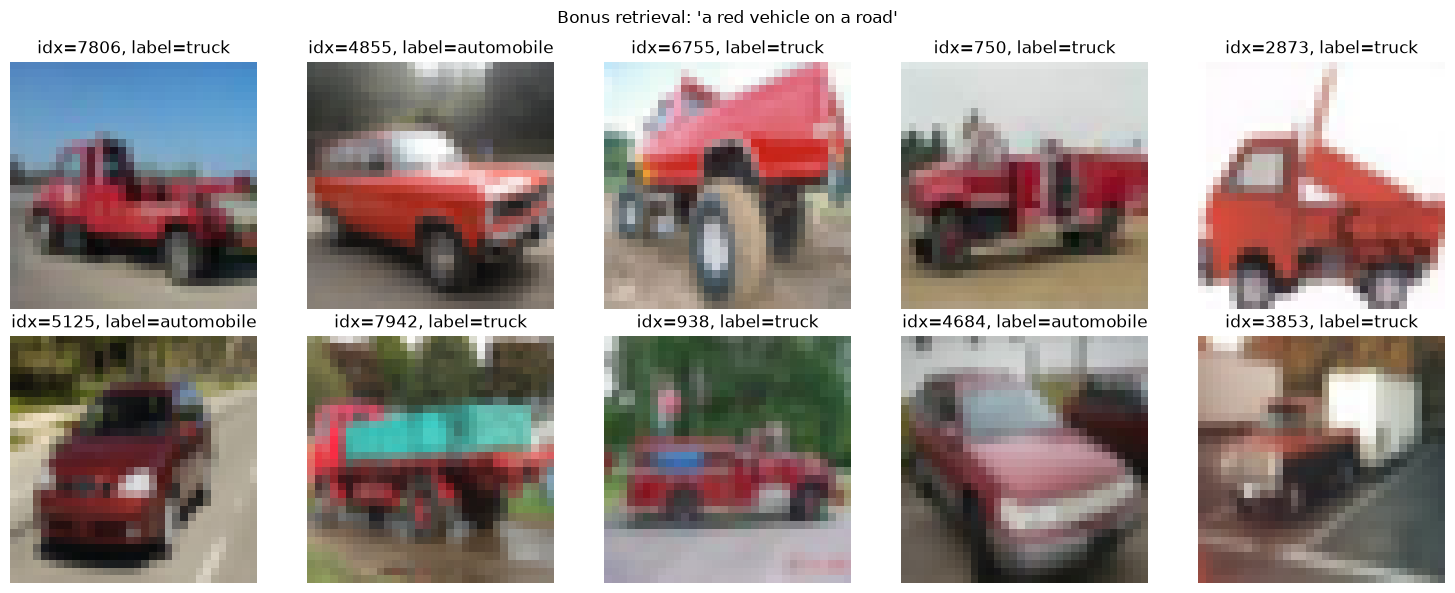

Бонусный запрос: 'a red vehicle on a road', top-10 индексы: [7806, 4855, 6755, 750, 2873, 5125, 7942, 938, 4684, 3853]
✔ bonus_retrieval.png сохранён
✔ bonus_query.json сохранён


In [47]:
# Собственный не-классовый запрос: "a red vehicle on a road"
# Получаем top-10 и сохраняем коллаж.
import matplotlib.pyplot as plt

bonus_query = "a red vehicle on a road"
topk_bonus, sims_bonus = retrieve_topk(bonus_query, k=10, image_feats=image_feats)

# Коллаж
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, idx in zip(axes.ravel(), topk_bonus):
    img, _ = ds.dataset[int(idx)]  # PIL image из исходного датасета
    ax.imshow(img)
    ax.set_title(f"idx={idx.item()}, label={classes[test_labels[idx]]}")
    ax.axis("off")
plt.suptitle(f"Bonus retrieval: {bonus_query!r}")
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_retrieval.png", dpi=150)
plt.show()

bonus_data = {
    "query": bonus_query,
    "top10_indices": topk_bonus.tolist(),
    "top10_labels": test_labels[topk_bonus].tolist(),
}
with open(ARTIFACTS / "bonus_query.json", "w") as f:
    json.dump(bonus_data, f, indent=2)

print(f"Бонусный запрос: {bonus_query!r}, top-10 индексы: {topk_bonus.tolist()}")
check((ARTIFACTS / "bonus_retrieval.png").exists(), "bonus_retrieval.png сохранён")
check((ARTIFACTS / "bonus_query.json").exists(), "bonus_query.json сохранён")

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


* **Zero-shot (5 шаблонов):** 0.8498–0.8618; лучший — `"a low resolution photo of a {}."` (0.8618), худший — `"a blurry photo of a {}."` (0.8498). Разброс 1.2 п.п. — формулировка шаблона влияет слабо.
* **Адаптация проекций:** accuracy 0.8511 → **0.9433** (+9.2 п.п.); mean precision@10 0.9600 → **1.0000**. Обучались только две линейные проекции 512×512 (~0.5M параметров), CLIP полностью заморожен.
* **Кривая обучения:** train loss 0.4232 → 0.1434 за 10 эпох, монотонно убывает, без NaN/переполнений.
* **Baseline P@10 по классам:** ошибки только на семантически близких парах — cat 0.90, dog 0.90, truck 0.80; остальные 7 классов — 1.00.
* **ΔP@10 после адаптации:** cat +0.10, dog +0.10, truck +0.20, остальные — 0.00. Адаптация исправляет именно близкие пары (cat↔dog, truck↔automobile) и не портит остальных.
* **Артефакт метрики:** после адаптации все 10 классов достигают P@10=1.00, поэтому в `search_examples.json` best_class == worst_class == `airplane` — это насыщение top-10 на CIFAR-10, а не ошибка; информативен baseline (worst = truck, P@10=0.80).
* **Ограничения:** CIFAR-10 (32×32 → апскейл до 224), 10 000 test-изображений; обучение по одному фиксированному шаблону `"a photo of a {}."`; только class-CE без hard-negative mining; `num_workers=0` (Windows/Jupyter).

## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


* CLIP ViT-B-32 zero-shot на CIFAR-10 даёт **0.85–0.86** accuracy; подбор словесного шаблона без обучения меняет результат на ≤1.2 п.п. — маргинальный рычаг по сравнению с адаптацией.
* Обучение двух линейных проекций (~0.5M параметров) на замороженном CLIP за 10 эпох CE по классовым прототипам даёт **+9.2 п.п. accuracy** (0.8511 → 0.9433) и **+4 п.п. mean precision@10** (0.96 → 1.00) — адаптация эффективна и дёшева.
* Прирост сосредоточен на семантически близких парах: truck↔automobile (+0.20), cat↔dog (+0.10); 7 из 10 классов не меняются — адаптация не ломает уже корректные предсказания.
* Zero-shot retrieval на CIFAR-10 упирается в потолок top-10 (P@10=1.0 у 7/10 классов **до** адаптации) — метрика насыщена и слабо различает модели; для сравнения нужны Recall@K при K≥50 или nDCG.
* Композиционный запрос `"a red vehicle on a road"` возвращает визуально согласованный top-10 (см. `bonus_retrieval.png`) — CLIP обобщает не-классовые атрибуты (цвет + объект + контекст) без дообучения.
* Артефакты эксперимента воспроизводимы: `SEED=42`, все метрики и чекпоинты в `lab_XX/artifacts/` (`zero_shot.json`, `retrieval_report.json`, `adaptation.json`, `retrieval_deltas.json`, `search_examples.json`, `clip_projection.pt`, `clip_index.pt`, `bonus_retrieval.png`, `bonus_query.json`).